
## Exercise 11.4 (Count the number of outliers in the original data set)   

- Use the original data set without gaps (pieces column) as input.
- Use an appropriate method to identify the outliers in the data set.
- Visualize the outliers and the original data set using seaborn.
- Count the number of detected outliers.
- Discuss the results.

# 1 Load the original data set without gaps

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL

# Lädt den Produktionsdatensatz aus dem Vorlesungsskript.
url = "https://noxthot.github.io/ws26_industrial_datascience_manuscript/data/assets/act1/selfstudysessions/sss1_production_data.csv"

# Liest die CSV-Datei ein und konvertiert die Spalte "Date" in das Datetime-Format.
df = pd.read_csv(url, parse_dates=["Date"])
df = df.set_index("Date")

# 2 Use an appropriate method to identify the outliers in the data set.

- STL auf Originalreihe pieces anwenden
- Residuen entnehmen. Rt = yt - Tt - St
    -> Abweichungen nach Abzug von Trend und Saison
- Ausreißer markieren mit 3 Sigma

In [3]:
# 1. Originalreihe in Trend, Saison und Rest zerlegen.
# Bei wöchentlichen Daten entspricht eine jährliche Saison etwa 52 Werten.
# robust=True verringert den Einfluss von Ausreißern auf die Zerlegung.
decomp_stl = STL(
    df["pieces"],
    period=52,
    robust=True
).fit()

# 2. Residuen entnehmen: Originalwerte minus Trend und saisonaler Anteil.
resid = decomp_stl.resid

# 3. Mittelwert und Standardabweichung der Residuen berechnen.
mean_resid = resid.mean()
std_resid = resid.std()

# 4. Grenzen nach der 3-Sigma-Regel festlegen.
lower_limit = mean_resid - 3 * std_resid
upper_limit = mean_resid + 3 * std_resid

# 5. Werte außerhalb der Grenzen als Ausreißer markieren.
outlier_mask = (resid < lower_limit) | (resid > upper_limit)

# Zugehörige Zeilen aus dem Originaldatensatz auswählen.
outliers = df.loc[outlier_mask].copy()

# Erkannte Ausreißer mit Datum und ursprünglicher Produktionsmenge anzeigen.
outliers[["pieces"]]

,pieces
Date,
2005-11-20,126.045360
2006-07-09,200.707220
2007-10-21,189.549387
2008-01-20,33.339621
2008-09-07,258.461672
2010-08-22,408.155436
2012-06-03,521.875486
2012-06-24,439.649168
2013-02-17,452.232118


# 3 Visualize the outliers and the original data set using seaborn.

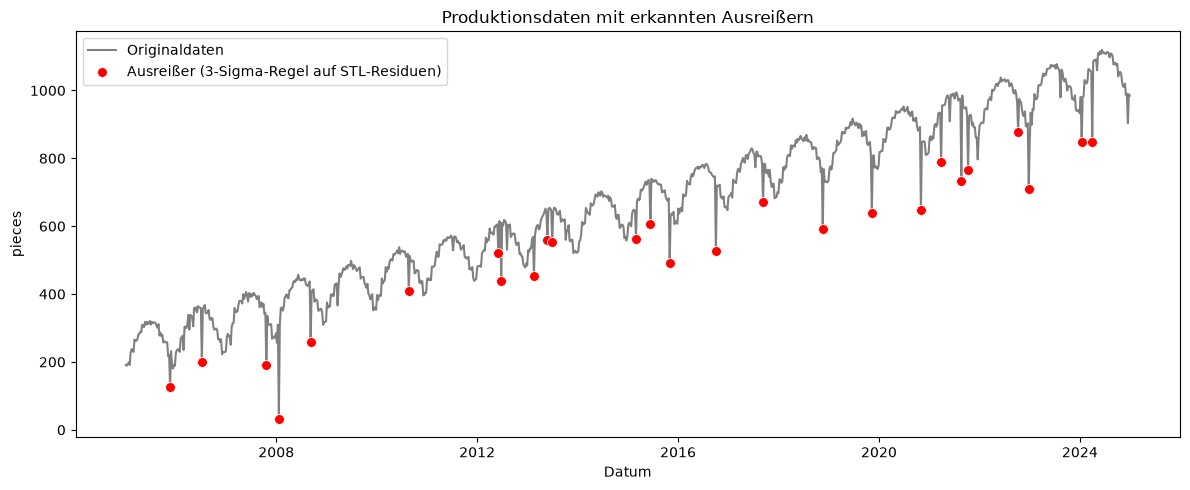

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

# Vollständige Originalreihe darstellen.
sns.lineplot(
    x=df.index,
    y=df["pieces"],
    color="grey",
    label="Originaldaten",
    ax=ax
)

# Erkannte Ausreißer an ihrer ursprünglichen Position markieren.
sns.scatterplot(
    x=outliers.index,
    y=outliers["pieces"],
    color="red",
    s=50,
    label="Ausreißer (3-Sigma-Regel auf STL-Residuen)",
    ax=ax,
    zorder=3
)

ax.set_title("Produktionsdaten mit erkannten Ausreißern")
ax.set_xlabel("Datum")
ax.set_ylabel("pieces")
ax.legend()

plt.tight_layout()
plt.show()

# 4 Count the number of detected outliers.

In [5]:
# Anzahl der erkannten Ausreißer zählen und ausgeben.
number_of_outliers = len(outliers)

print("Anzahl der erkannten Ausreißer:", number_of_outliers)

Anzahl der erkannten Ausreißer: 26


# 5 Discuss the results.

Mit der STL-Zerlegung und der 3-Sigma-Regel wurden 26 Ausreißer erkannt. Trend und jährliche Schwankungen werden dabei berücksichtigt. Alle erkannten Ausreißer sind Abweichungen nach unten und im Diagramm als deutliche Produktionseinbrüche sichtbar.

Die Anzahl hängt von der gewählten Grenze und der STL-Zerlegung ab. Kleinere Auffälligkeiten können unentdeckt bleiben. Die markierten Werte sind nicht zwingend Messfehler, sondern könnten auch tatsächliche Produktionsstillstände darstellen.

ipynb exportiert als html mit:

uv run jupyter nbconvert --to html "Tasks/11 Self study - Session 2/Exercise_11.4.ipynb"